# India in EM-DAT, with detection

Does 12's model, the event likelihood with population-dependent detection, carry from Laos's 36 events to India's record, and what does that record say about where climate-related events start?

The record is EM-DAT's hydrometeorological and climatological events in India from 1990 to 2023, placed on GADM units by EM-DAT's own coding where it has one and by Geo-Disasters' footprints otherwise. An event with neither is recorded at the country level. The model is 12's unchanged, on a 25 km lattice instead of 10 km, since India is about 14 times the area of Laos.

In [61]:
import os

from pathlib import Path

# Keras reads its backend once, when bayesflow first imports it.
os.environ.setdefault("KERAS_BACKEND", "jax")

import arviz as az
import bayesflow as bf
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import pymc as pm
import pytensor.tensor as pt
import xarray as xr

from arviz_plots import PlotCollection
from scipy import fft
from tqdm.auto import tqdm

from climate_risk.data.gadm import administered_territories, load_units_in_country
from climate_risk.data.geo_disasters import load_resolved_units
from climate_risk.data.ghsl import population_on_cells
from climate_risk.data_functions.emdat_processing import DISASTER_CLASSES, event_geography, load_emdat_events
from climate_risk.data_functions.rivers_data_loader import load_rivers_data
from climate_risk.geo.crs import PROJECTED_CRS, to_km
from climate_risk.geo.distance import get_distance_to
from climate_risk.geo.raster import assign_cells_to_units, build_cell_grid, dissolve_place_boundary
from climate_risk.models.aggregation import Aggregation
from climate_risk.plotting import configure_plot_style

configure_plot_style()

CACHE_DIR = Path("../../data")
ISO = "IND"
SEED = 20261023

## Geography

Atoms are the cells of a 25 km lattice over India. Each atom belongs to the ADM1 and ADM2 unit covering most of it.

In [2]:
RESOLUTION_KM = 25.0
LEVELS = ("ADM2", "ADM1", "ADM0")

# GADM files the territories India administers in Kashmir and along the Chinese border under codes of their own.
CODES = (ISO, *administered_territories(ISO, CACHE_DIR))
units = {level: pd.concat([load_units_in_country(code, admin, CACHE_DIR) for code in CODES], ignore_index=True)
         for level, admin in [("ADM2", 2), ("ADM1", 1)]}
boundary = dissolve_place_boundary(units["ADM1"][["geometry"]], iso3=ISO)
units["ADM0"] = gpd.GeoDataFrame({"gid": [ISO], "name": ["India"], "admin_level": [0]}, geometry=boundary.geometry.to_numpy(), crs=boundary.crs)
grid = build_cell_grid(boundary, resolution_km=RESOLUTION_KM)
atoms = grid.cells.reset_index(drop=True)
n_atoms = len(atoms)
column_of_cell = pd.Series(np.arange(n_atoms), index=atoms["cell_id"].to_numpy())

# Every (atom, unit) pair that overlaps, with units as positions into units[level].
overlaps = {}
for level in LEVELS:
    pairs = assign_cells_to_units(grid, units[level])
    position = pd.Series(np.arange(len(units[level])), index=units[level]["gid"].to_numpy())
    overlaps[level] = pd.DataFrame({"atom": column_of_cell.loc[pairs["cell_id"]].to_numpy(),
                                    "unit": position.loc[pairs["gid"]].to_numpy(),
                                    "coverage": pairs["coverage"].to_numpy()})

# The unit covering most of each atom, which is the unit an event centered there is reported in.
unit_of_atom = {level: overlaps[level].sort_values("coverage", ascending=False).drop_duplicates("atom").set_index("atom")["unit"].reindex(np.arange(n_atoms)).to_numpy()
                for level in LEVELS}
n_units = {level: len(units[level]) for level in LEVELS}
unit_offset = dict(zip(LEVELS, np.cumsum([0, *[n_units[level] for level in LEVELS[:-1]]]), strict=True))
n_all_units = sum(n_units.values())

pd.Series({
    "territory codes": ", ".join(CODES),
    "atoms": n_atoms,
    **{f"{level} units": n_units[level] for level in LEVELS},
    **{f"{level} units dominating no atom": n_units[level] - len(np.unique(unit_of_atom[level])) for level in LEVELS},
})

territory codes                  IND, Z01, Z04, Z05, Z07, Z09
atoms                                                    5607
ADM2 units                                                676
ADM1 units                                                 41
ADM0 units                                                  1
ADM2 units dominating no atom                              17
ADM1 units dominating no atom                               3
ADM0 units dominating no atom                               0
dtype: object

## Covariate and population

As in 12: the hazard covariate is the standardized log distance from each atom to the nearest major river in HydroRIVERS, and each unit's detection covariate is its 2005 GHS-POP log population, standardized across the units of its level.

In [3]:
POPULATION_EPOCH = 2005
COVARIATE_NAMES = ("log distance to river",)


def standardized(values):
    """Values shifted to mean zero and scaled to unit standard deviation."""
    return (values - values.mean()) / values.std()


rivers = load_rivers_data(CACHE_DIR)
river_km = to_km(get_distance_to(rivers.cx[boundary.total_bounds[0] - 1:boundary.total_bounds[2] + 1, boundary.total_bounds[1] - 1:boundary.total_bounds[3] + 1], atoms)["distance_to_closest"].to_numpy())
covariates = standardized(np.log(river_km + 1.0))[:, None]

population = population_on_cells(grid, POPULATION_EPOCH, CACHE_DIR)
unit_population = {level: np.bincount(unit_of_atom[level], weights=population, minlength=n_units[level]) for level in LEVELS}
population_z = np.concatenate([
    standardized(np.log(np.maximum(unit_population[level], 1.0))) if n_units[level] > 1 else np.zeros(1)
    for level in LEVELS
])

# Projected atom centers, scaled so the longer side of India spans one unit, the domain the lengthscale prior assumes.
projected = atoms.to_crs(PROJECTED_CRS).geometry
atom_xy = np.column_stack([projected.x, projected.y])
DOMAIN_KM = to_km(np.ptp(atom_xy, axis=0).max())
atom_centroids = (atom_xy - atom_xy.min(axis=0)) / np.ptp(atom_xy, axis=0).max()

pd.Series({
    "river distance, median km": np.median(river_km),
    "river distance, max km": river_km.max(),
    "population, millions": population.sum() / 1e6,
    "correlation of log population density with river covariate": np.corrcoef(np.log1p(population / atoms["place_area_km2"]), covariates[:, 0])[0, 1],
    "domain side, km": DOMAIN_KM,
}).round(2)

river distance, median km                                      36.15
river distance, max km                                        946.37
population, millions                                         1152.99
correlation of log population density with river covariate     -0.13
domain side, km                                              3431.02
dtype: float64

## The record

As in 12: EM-DAT's GADM coding first, Geo-Disasters for ground EM-DAT leaves unnamed, an event naming both levels reported at the coarser one, and an event naming nothing reported at ADM0. A unit EM-DAT names outside the territory India administers, in Pakistan-administered Kashmir, is dropped from the event's named set. Geo-Disasters' footprints are overlaid on India's own GADM units only, so in the administered territories an event's units come from EM-DAT's coding alone.

In [85]:
FIRST_YEAR, LAST_YEAR = 1990, 2023
LEVEL_OF_ADMIN = {2: "ADM2", 1: "ADM1"}

events = load_emdat_events(CACHE_DIR).filter(
    (pl.col("ISO") == ISO)
    & pl.col("Disaster Type").is_in(list(DISASTER_CLASSES))
    & pl.col("date").dt.year().is_between(FIRST_YEAR, LAST_YEAR)
)
resolved = pl.from_pandas(load_resolved_units([ISO], CACHE_DIR)).select(
    pl.col("DisNo."),
    pl.col("gid"),
    pl.col("name"),
    pl.col("admin_level").cast(pl.Int8),
    pl.col("geocoding_q").cast(pl.Int8),
    pl.col("overlap"),
)
geography = event_geography(events, resolved=resolved)

position = {level: pd.Series(np.arange(n_units[level]), index=units[level]["gid"].to_numpy()) for level in ("ADM2", "ADM1")}
outside_india = geography.filter(pl.col("gid").is_not_null()
                                 & ~pl.col("gid").is_in(pd.concat(position.values()).index.to_list()))
# GADM gids nest, so district IND.15.3_1 lies in state IND.15_1.
state_of_district = position["ADM1"].loc[units["ADM2"]["gid"].str.replace(r"\.\d+_1$", "_1", regex=True)].to_numpy()


def named_units(rows):
    """The units an event names, as positions into units[level], keyed by level."""
    named = {}
    for admin, gid in rows.filter(pl.col("gid").is_not_null()).select("admin_level", "gid").iter_rows():
        level = LEVEL_OF_ADMIN[admin]
        if gid in position[level].index:
            named.setdefault(level, set()).add(int(position[level].loc[gid]))

    return {level: tuple(sorted(found)) for level, found in named.items()}


def provinces_of(named):
    """Positions of the provinces an event names, directly or as the state of a named district, empty when it names neither."""
    return frozenset(named.get("ADM1", ())) | frozenset(state_of_district[list(named.get("ADM2", ()))].tolist())


event_rows = []
for (disno,), rows in geography.group_by("DisNo.", maintain_order=True):
    named = named_units(rows)
    event_rows.append({
        "DisNo.": disno,
        "level": "ADM1" if "ADM1" in named else "ADM2" if named else "ADM0",
        "named": named or {"ADM0": (0,)},
        "provinces": provinces_of(named),
        "source": "+".join(sorted(set(rows["geometry_source"]))),
    })

record = pd.DataFrame(event_rows).merge(events.select("DisNo.", "Disaster Type", pl.col("date").dt.year().alias("year")).to_pandas(), on="DisNo.")

print(f"{outside_india.height} named units outside India's GADM units, in {outside_india['DisNo.'].n_unique()} events: {sorted(set(outside_india['gid']))}")
pd.concat([
    record.groupby("level").size().rename("events"),
    record.groupby(["level", "source"]).size().unstack(fill_value=0),
], axis=1)

29 named units outside India's GADM units, in 15 events: ['Z06.1_1', 'Z06.6_1']


,events,country,emdat_point,gadm,gadm+geo_disasters,geo_disasters
level,,,,,,
ADM0,15,13,1,1,0,0
ADM1,283,0,0,169,29,85
ADM2,154,0,0,133,5,16


## The model

12's model with two changes for a record this long. Recorded events are counted by year, negative binomial around a mean that a smooth year effect scales up and down: a 1D HSGP over years with a Matern 5/2 kernel and a lengthscale prior with its mode at 5 years. The year effect follows changes in how completely EM-DAT records India, and the dispersion takes the single years that cluster. A year effect scales the whole map at once, so it cancels from each record's share of the recorded intensity, and the record term is unchanged.

The intercept's prior is scaled to India, and the spatial lengthscale prior is in units of the domain's longer side, about 3,400 km here, so its mode sits near 340 km.

In [62]:
HSGP_BOUNDARY_FACTOR = 4.0
HSGP_BASIS_PER_AXIS = 50
YEAR_BOUNDARY_FACTOR = 1.5
YEAR_BASIS = 20
OFFSET_SD_PRIOR = 0.5
OFFSET_LEVELS = ("ADM2", "ADM1")
# A prior guess at the event centers over the whole record, recorded or not, which fixes where the intercept sits.
PRIOR_EVENT_CENTERS = 1_000
sample_kwargs = {
    "chains": 8,
    "cores": 8,
    "tune": 500,
    "draws": 250,
    "target_accept": 0.9,
    "nuts_sampler": "nutpie",
    "random_seed": SEED,
}

years = np.arange(FIRST_YEAR, LAST_YEAR + 1)
YEARS = len(years)
annual_observed = record.groupby("year").size().reindex(years, fill_value=0).to_numpy()

# Each (level, atom) in one flat index, level-major, and the all-units index of the atom's unit at that level.
center_unit = np.concatenate([unit_offset[level] + unit_of_atom[level] for level in LEVELS])


def union_cells(named):
    """The (level, atom) cells of an event's union, read at the level it is reported at."""
    level = "ADM1" if "ADM1" in named else next(iter(named))
    atoms_named = np.unique(np.concatenate([overlaps[at]["atom"][overlaps[at]["unit"].isin(found)].to_numpy() for at, found in named.items()]))

    return LEVELS.index(level), LEVELS.index(level) * n_atoms + atoms_named


record_key = record["named"].map(lambda named: tuple(sorted(named.items())))
distinct = record.assign(key=record_key).groupby("key", sort=False).agg(multiplicity=("DisNo.", "size"), named=("named", "first"))
cells_by_record = [union_cells(named) for named in distinct["named"]]
detection_terms = {
    "multiplicity": distinct["multiplicity"].to_numpy(),
    "union": Aggregation(units=tuple(f"record {index}" for index in range(len(distinct))),
                         rows=np.repeat(np.arange(len(distinct)), [len(cells) for _, cells in cells_by_record]),
                         columns=np.concatenate([cells for _, cells in cells_by_record]),
                         weights=np.ones(sum(len(cells) for _, cells in cells_by_record)),
                         n_cells=len(LEVELS) * n_atoms),
}
COORDS = {
    "covariate": list(COVARIATE_NAMES),
    "atom": np.arange(n_atoms),
    "unit": np.arange(n_all_units),
    "level": list(LEVELS),
    "record": detection_terms["union"].units,
    "year": years,
    **{level: units[level]["gid"].to_list() for level in OFFSET_LEVELS},
}


def hsgp_field(amplitude, lengthscale):
    """The field at every atom, a Hilbert space approximation to a Matern 3/2 GP."""
    gp = pm.gp.HSGP(m=[HSGP_BASIS_PER_AXIS, HSGP_BASIS_PER_AXIS],
                    c=HSGP_BOUNDARY_FACTOR,
                    cov_func=amplitude**2 * pm.gp.cov.Matern32(input_dim=2, ls=lengthscale))

    return gp.prior("field", X=atom_centroids, dims="atom")


def latent_log_rate(field_prior):
    """The log rate of event centers at every atom, built inside the current model, with the field from ``field_prior(amplitude, lengthscale)``."""
    intercept = pm.Normal("intercept",
                          mu=np.log(PRIOR_EVENT_CENTERS / n_atoms),
                          sigma=1.0)
    slopes = pm.Normal("slopes",
                       mu=0.0,
                       sigma=1.0,
                       dims="covariate")

    # Mode at 0.1 of the domain, with a tail out past half its width.
    field_lengthscale = pm.InverseGamma("field_lengthscale",
                                        alpha=3.0,
                                        beta=0.4)
    field_amplitude = pm.HalfNormal("field_amplitude", sigma=1.0)
    field = field_prior(field_amplitude, field_lengthscale)

    offset_part = 0.0
    for level in OFFSET_LEVELS:
        offset_sd = pm.HalfNormal(f"{level}_offset_sd", sigma=OFFSET_SD_PRIOR)
        standard = pm.Normal(f"{level}_offset_standard",
                             mu=0.0,
                             sigma=1.0,
                             dims=level)
        offsets = pm.Deterministic(f"{level}_offset", offset_sd * standard, dims=level)
        offset_part = offset_part + offsets[unit_of_atom[level]]

    return pm.Deterministic("log_rate",
                            intercept + pm.math.dot(covariates, slopes) + field + offset_part,
                            dims="atom")


def recorded_intensity(field_prior):
    """Recorded events per (level, atom) over the record: centers, times the level's share, times detection by the center's unit there."""
    rate = pm.math.exp(latent_log_rate(field_prior))
    naming_intercept = pm.Normal("naming_intercept",
                                 mu=0.0,
                                 sigma=1.5)
    naming_slope = pm.Normal("naming_slope",
                             mu=0.0,
                             sigma=1.0)
    naming = pm.Deterministic("naming_probability",
                              pm.math.invlogit(naming_intercept + naming_slope * population_z),
                              dims="unit")
    level_probability = pm.Dirichlet("level_probability",
                                     a=np.ones(len(LEVELS)),
                                     dims="level")

    return level_probability[:, None] * rate[None, :] * naming[center_unit].reshape((len(LEVELS), n_atoms))


def annual_count(recorded, observed=None):
    """Recorded events in each year: negative binomial around the record's annual mean, scaled by a smooth year effect."""
    # Mode at 5 years, so the effect follows changes in reporting over a few years and leaves single years to the dispersion.
    year_lengthscale = pm.InverseGamma("year_lengthscale",
                                       alpha=3.0,
                                       beta=20.0)
    year_amplitude = pm.HalfNormal("year_amplitude", sigma=0.5)
    gp = pm.gp.HSGP(m=[YEAR_BASIS],
                    c=YEAR_BOUNDARY_FACTOR,
                    cov_func=year_amplitude**2 * pm.gp.cov.Matern52(input_dim=1, ls=year_lengthscale))
    year_effect = gp.prior("year_effect", X=years[:, None].astype(float), dims="year")
    overdispersion = pm.HalfNormal("overdispersion", sigma=1.0)

    return pm.NegativeBinomial("annual_count",
                               mu=recorded.sum() / YEARS * pt.exp(year_effect),
                               alpha=1.0 / overdispersion,
                               observed=observed,
                               dims="year")


def counted_logp(count, probability):
    """Log probability of ``count`` events sharing one record, given the record's probability under the model."""
    return count * pt.log(probability)


def build_event_detection_model():
    """The event likelihood with detection by the center's unit, and recorded counts that vary by year."""
    terms = detection_terms

    with pm.Model(coords=COORDS) as model:
        recorded = recorded_intensity(field_prior=hsgp_field)
        recorded_rate = pm.Deterministic("recorded_rate", recorded.sum())

        annual_count(recorded, observed=annual_observed)
        # A year effect scales the whole map, so it cancels from each record's share of the recorded intensity.
        pm.CustomDist("record_count",
                      terms["union"].aggregate_symbolic(recorded.ravel()) / recorded_rate,
                      logp=counted_logp,
                      observed=terms["multiplicity"],
                      dims="record")

    return model


event_detection_model = build_event_detection_model()

pd.Series({
    "distinct records": len(distinct),
    "largest union, atoms": int(np.bincount(detection_terms["union"].rows).max()),
    "free parameters": sum(value.size for value in event_detection_model.initial_point().values()),
})

distinct records         337
largest union, atoms    5607
free parameters         3250
dtype: int64

## Prior predictive

How many recorded events over 34 years the priors allow before seeing the record.

Sampling: [ADM1_offset_sd, ADM1_offset_standard, ADM2_offset_sd, ADM2_offset_standard, annual_count, field_amplitude, field_hsgp_coeffs, field_lengthscale, intercept, level_probability, naming_intercept, naming_slope, overdispersion, slopes, year_amplitude, year_effect_hsgp_coeffs, year_lengthscale]


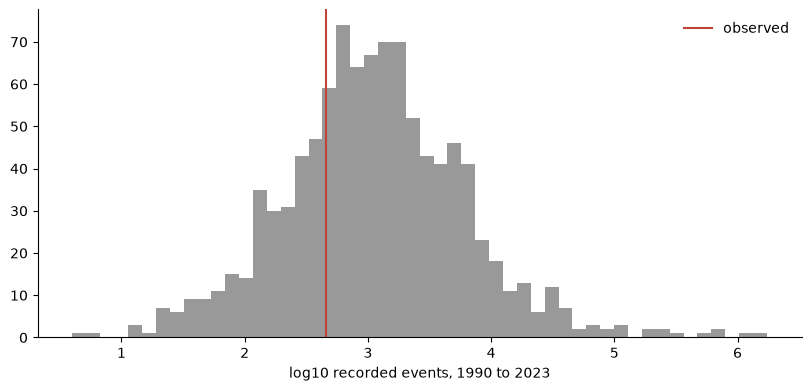

In [6]:
PRIOR_DRAWS = 1_000

with event_detection_model:
    prior = pm.sample_prior_predictive(draws=PRIOR_DRAWS,
                                       var_names=["annual_count"],
                                       random_seed=SEED)

# Recorded counts span orders of magnitude under the prior, so they are compared on a log scale.
figure, axis = plt.subplots(figsize=(8, 3.8))
axis.hist(np.log10(prior.prior_predictive["annual_count"].sum("year").to_numpy().ravel() + 1),
          bins=50,
          color="0.6")
axis.axvline(np.log10(annual_observed.sum() + 1),
             color="#c1443c",
             label="observed")
axis.set_xlabel("log10 recorded events, 1990 to 2023")
axis.legend(frameon=False)
plt.show()

## Fit

In [7]:
FIT_PATH = Path("fits/13_india_nuts.nc")

if FIT_PATH.exists():
    fit = az.from_netcdf(FIT_PATH)
else:
    with event_detection_model:
        fit = pm.sample(**sample_kwargs)
    fit.to_netcdf(FIT_PATH)

In [8]:
SUMMARY_VARIABLES = ["intercept", "slopes", "field_amplitude", "field_lengthscale", "ADM2_offset_sd", "ADM1_offset_sd", "naming_intercept", "naming_slope", "level_probability", "year_amplitude", "year_lengthscale", "overdispersion", "recorded_rate"]
every_free = az.summary(fit, var_names=[variable.name for variable in event_detection_model.free_RVs])

pd.concat([
    az.summary(fit, var_names=SUMMARY_VARIABLES),
    pd.DataFrame({"r_hat": [every_free["r_hat"].max()], "ess_bulk": [every_free["ess_bulk"].min()]}, index=["worst over every free parameter"]),
    pd.DataFrame({"mean": [int(fit.sample_stats["diverging"].sum())]}, index=["divergences"]),
]).round(2)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
intercept,-2.06,0.72,-3.24,-0.88,216.37,314.29,1.03,0.05,0.02
slopes[log distance to river],-1.22,0.19,-1.54,-0.92,391.11,426.07,1.02,0.01,0.00
field_amplitude,0.87,0.42,0.20,1.56,232.26,202.20,1.03,0.03,0.01
field_lengthscale,0.16,0.10,0.06,0.33,563.59,504.45,1.01,0.00,0.01
ADM2_offset_sd,2.05,0.23,1.70,2.42,237.81,489.39,1.03,0.01,0.01
ADM1_offset_sd,0.44,0.28,0.04,0.91,329.00,378.33,1.02,0.02,0.01
naming_intercept,-4.05,0.78,-5.26,-2.80,154.21,305.42,1.03,0.06,0.03
naming_slope,2.28,0.55,1.42,3.15,234.95,405.89,1.04,0.04,0.02
level_probability[ADM2],0.49,0.05,0.42,0.56,363.12,643.99,1.02,0.00,0.00
level_probability[ADM1],0.42,0.06,0.32,0.51,253.52,465.45,1.03,0.00,0.00


## Posterior against prior

Sampling: [ADM1_offset_sd, ADM2_offset_sd, field_amplitude, field_lengthscale, intercept, level_probability, naming_intercept, naming_slope, overdispersion, slopes, year_amplitude, year_lengthscale]


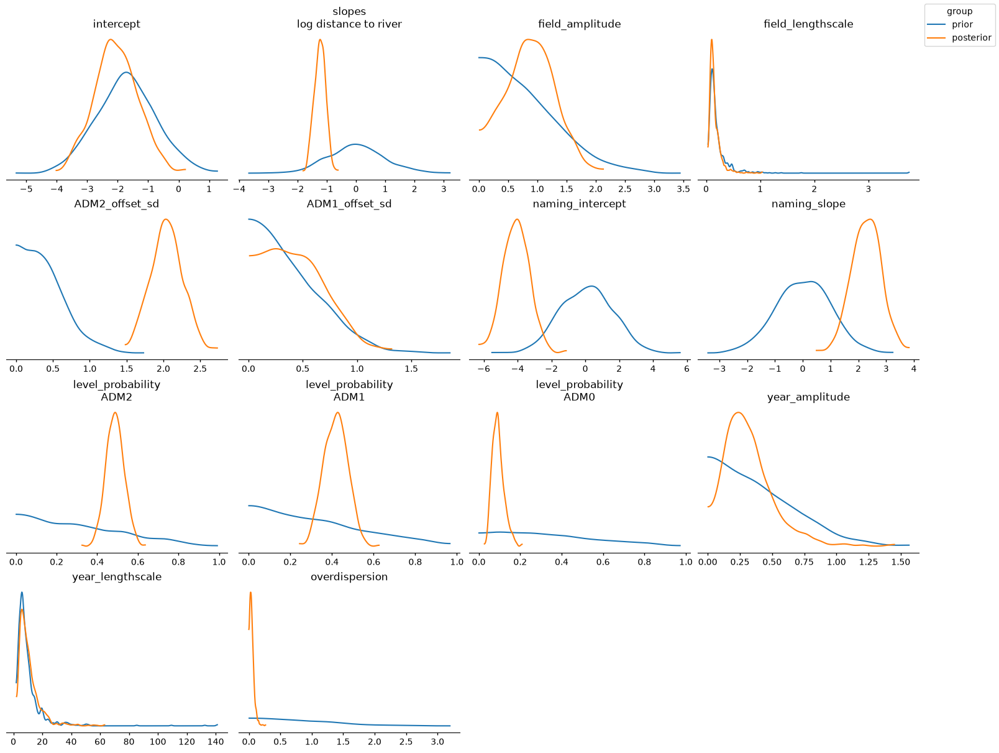

In [9]:
PARAMETERS = ["intercept", "slopes", "field_amplitude", "field_lengthscale", "ADM2_offset_sd", "ADM1_offset_sd", "naming_intercept", "naming_slope", "level_probability", "year_amplitude", "year_lengthscale", "overdispersion"]

with event_detection_model:
    fit["prior"] = pm.sample_prior_predictive(draws=PRIOR_DRAWS,
                                              var_names=PARAMETERS,
                                              random_seed=SEED)["prior"]

az.plot_prior_posterior(fit,
                        var_names=PARAMETERS,
                        col_wrap=4,
                        figure_kwargs={"figsize": (16, 12)})
plt.show()

posterior = fit.posterior
adm2_units = slice(unit_offset["ADM2"], unit_offset["ADM2"] + n_units["ADM2"])

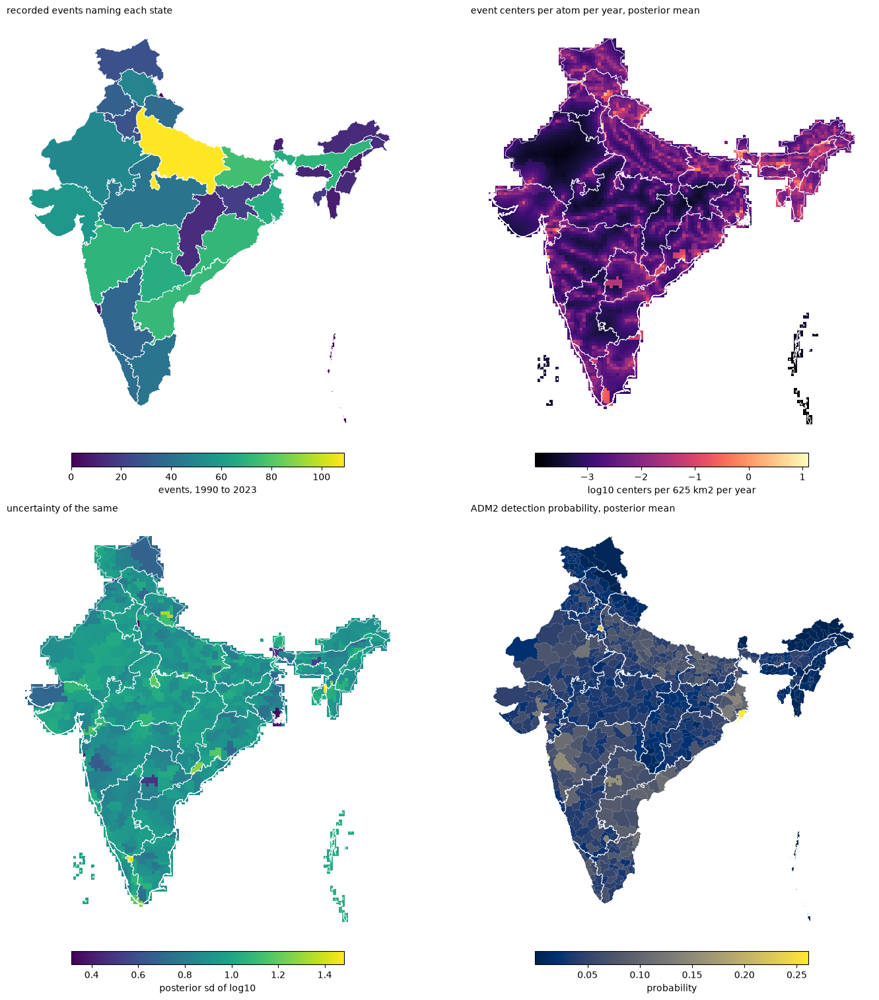

In [87]:
atom_cells = gpd.GeoDataFrame(geometry=grid.footprints.reset_index(drop=True), crs=grid.footprints.crs)
adm1_borders = units["ADM1"].boundary

log10_annual = (posterior["log_rate"] - np.log(YEARS)) / np.log(10)
events_naming = np.bincount([province for found in record["provinces"] for province in found], minlength=n_units["ADM1"])

panels = {
    "recorded events naming each state": (units["ADM1"].assign(value=events_naming), "viridis", "events, 1990 to 2023"),
    "event centers per atom per year, posterior mean": (atom_cells.assign(value=log10_annual.mean(("chain", "draw")).to_numpy()), "magma", "log10 centers per 625 km2 per year"),
    "uncertainty of the same": (atom_cells.assign(value=log10_annual.std(("chain", "draw")).to_numpy()), "viridis", "posterior sd of log10"),
    "ADM2 detection probability, posterior mean": (units["ADM2"].assign(value=posterior["naming_probability"].isel(unit=adm2_units).mean(("chain", "draw")).to_numpy()), "cividis", "probability"),
}

figure, axes = plt.subplots(2, 2, figsize=(14, 15))
for axis, (title, (frame, cmap, label)) in zip(axes.ravel(), panels.items(), strict=True):
    frame.plot(column="value",
               ax=axis,
               cmap=cmap,
               legend=True,
               legend_kwds={"label": label, "shrink": 0.6, "location": "bottom", "pad": 0.02})
    adm1_borders.plot(ax=axis,
                      color="white",
                      linewidth=0.5)
    axis.set_axis_off()
    axis.set_title(title, loc="left", fontsize=10)
plt.show()

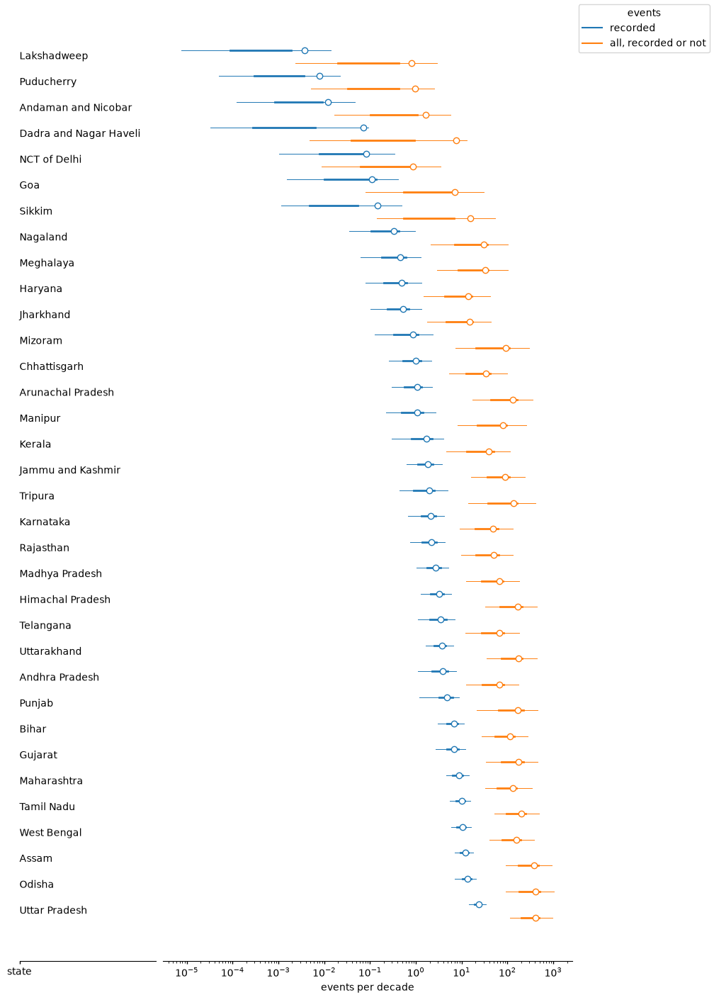

In [11]:
DECADE = 10

# GADM splits some states across territory codes, so atoms are grouped by the state's name.
state_of_atom = xr.DataArray(units["ADM1"]["name"].to_numpy()[unit_of_atom["ADM1"]], dims="atom", name="state")
rate = np.exp(posterior["log_rate"])
detection = (posterior["level_probability"]
             * posterior["naming_probability"].isel(unit=xr.DataArray(center_unit.reshape(len(LEVELS), n_atoms), dims=("level", "atom")))).sum("level")

per_decade = xr.concat([(rate * detection).groupby(state_of_atom).sum(),
                        rate.groupby(state_of_atom).sum()],
                       dim=pd.Index(["recorded", "all, recorded or not"], name="events")) * DECADE / YEARS
per_decade = per_decade.sortby(per_decade.sel(events="recorded").mean(("chain", "draw"))).transpose("chain", "draw", "state", "events")

forest = az.plot_forest(per_decade.to_dataset(name="events per decade"),
                        combined=True,
                        labels=["state"],
                        aes={"color": ["events"]},
                        figure_kwargs={"figsize": (10, 14)})
forest.add_legend("events")
# Recorded and total events differ by an order of magnitude, so both are read on a log scale.
interval_axis = forest.viz["figure"].item().axes[-1]
interval_axis.set_xscale("log")
interval_axis.set_xlabel("events per decade")
plt.show()

India's record identifies more than Laos's did, and some of what it identifies is an artifact. The river slope is -1.23 with an 89% interval from -1.52 to -0.92, tighter than Laos's and in the same direction. The naming slope is 2.38 (1.49 to 3.23), so records concentrate in populous districts far beyond what the rate explains. The level of detection is not identified, as in 11 and 12: the median district detection probability is 0.027 (0.008 to 0.081 over 90% of draws), so the 452 recorded events imply about 9,700 event centers over the record (3,000 to 32,000), a total set by the priors on the rate's intercept and on detection, not by the record.

The district offsets have a standard deviation of 2.06 against a prior scale of 0.5, and the largest sit in districts smaller than an atom. Baghpat, which no event names, has an offset of 6.1, and Mumbai Suburban, 2 atoms named by 6 events, has 4.5. A district smaller than a 25 km atom shares its atoms with its neighbors, so an event naming it puts its center in atoms that belong to a neighbor, and the neighbor's offset absorbs it. Uttar Pradesh, Odisha and Assam lead in recorded events, and the forest's ordering among the small union territories at the top reflects their size more than their hazard. The forest spreads each state's record-wide rate evenly over the 34 years, so it shows an average decade, not any particular one.

## Posterior predictive check

As in 12: a predictive model on the fit's `recorded_intensity`, with recorded events counted by reporting level, by decade and by year, drawn with `sample_posterior_predictive`.

In [12]:
DECADES = {"1990s": (1990, 1999), "2000s": (2000, 2009), "2010 to 2023": (2010, 2023)}


def build_predictive_model():
    """The fitted model's recorded counts by year, summed by decade and split by reporting level."""
    with pm.Model(coords=COORDS | {"decade": list(DECADES)}) as model:
        recorded = recorded_intensity(field_prior=hsgp_field)
        counts = annual_count(recorded)
        pm.Deterministic("decade_count",
                         pt.stack([counts[np.flatnonzero((years >= first) & (years <= last))].sum() for first, last in DECADES.values()]),
                         dims="decade")
        pm.Multinomial("level_count",
                       n=counts.sum(),
                       p=recorded.sum(axis=1) / recorded.sum(),
                       dims="level")

    return model


with build_predictive_model():
    ppc = pm.sample_posterior_predictive(fit,
                                         var_names=["annual_count", "decade_count", "level_count"],
                                         random_seed=SEED)

ppc["observed_data"] = xr.Dataset({
    "level_count": ("level", record["level"].value_counts().reindex(LEVELS, fill_value=0).to_numpy()),
    "decade_count": ("decade", [annual_observed[(years >= first) & (years <= last)].sum() for first, last in DECADES.values()]),
    "annual_count": ("year", annual_observed),
}, coords=ppc.posterior_predictive.coords).drop_vars(["chain", "draw"])

Sampling: [annual_count, level_count]


Output()

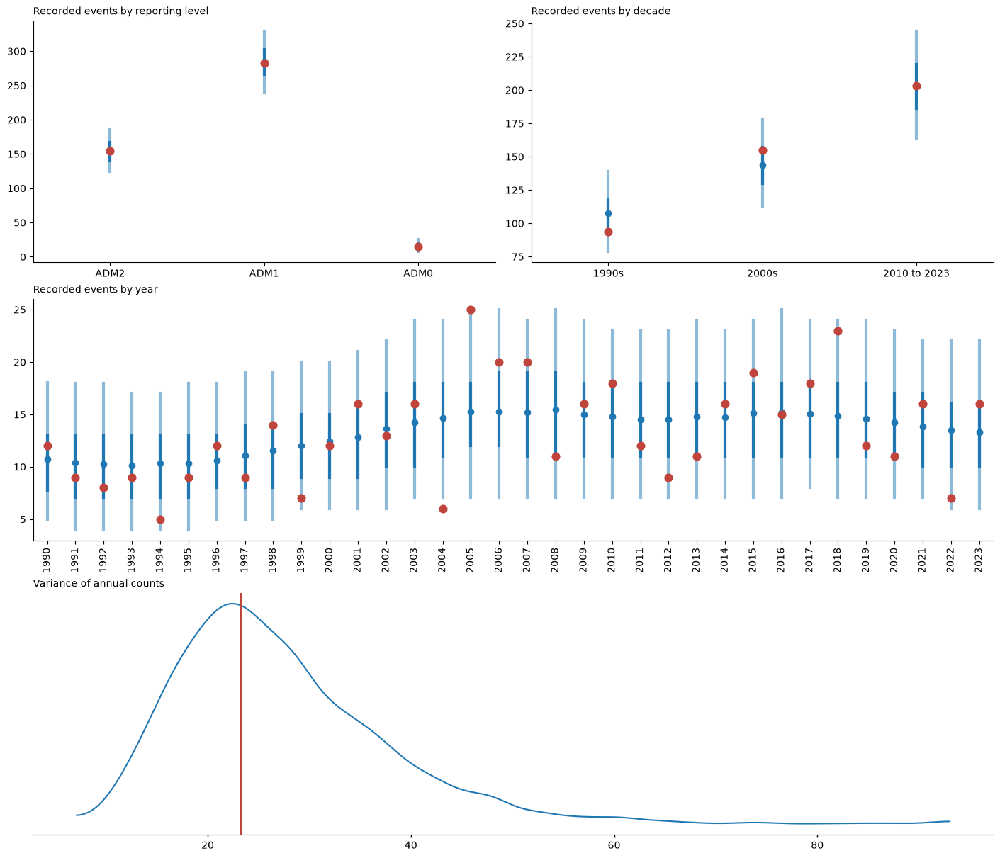

In [13]:
OBSERVED_COLOR = "#c1443c"
OBSERVED_MARKERS = {"color": OBSERVED_COLOR, "marker": "o", "size": 60, "zorder": 4}


def plot_collection_on(axis, variable):
    """A PlotCollection drawing ``variable`` onto an existing axis, so ArviZ plots share one figure."""
    viz = xr.DataTree.from_dict({
        "/": xr.Dataset({"figure": np.array(axis.figure, dtype=object)}),
        "plot": xr.Dataset({variable: np.array(axis, dtype=object)}),
        "row_index": xr.Dataset({variable: 0}),
        "col_index": xr.Dataset({variable: 0}),
    })

    return PlotCollection(ppc.posterior_predictive.dataset[[variable]], viz, backend="matplotlib")


figure = plt.figure(figsize=(14, 12))
layout = figure.add_gridspec(3, 2)
level_axis = figure.add_subplot(layout[0, 0])
decade_axis = figure.add_subplot(layout[0, 1])
annual_axis = figure.add_subplot(layout[1, :])
spread_axis = figure.add_subplot(layout[2, :])

for axis, variable in [(level_axis, "level_count"), (decade_axis, "decade_count"), (annual_axis, "annual_count")]:
    az.plot_ppc_interval(ppc,
                         var_names=[variable],
                         plot_collection=plot_collection_on(axis, variable),
                         visuals={"observed_markers": OBSERVED_MARKERS})
az.plot_ppc_tstat(ppc,
                  var_names=["annual_count"],
                  t_stat="var",
                  plot_collection=plot_collection_on(spread_axis, "annual_count"),
                  visuals={"title": False, "observed_tstat": False})
spread_axis.axvline(float(ppc.observed_data["annual_count"].var()),
                    color=OBSERVED_COLOR)

for axis, coordinate, title in [(level_axis, "level", "Recorded events by reporting level"),
                                (decade_axis, "decade", "Recorded events by decade"),
                                (annual_axis, "year", "Recorded events by year")]:
    labels = ppc.observed_data[coordinate].to_numpy()
    axis.set_xticks(np.arange(len(labels)), labels, rotation=90 if coordinate == "year" else 0)
    axis.set_xlim(-0.5, len(labels) - 0.5)
    axis.set_xlabel("")
    axis.set_ylabel("")
    axis.set_title(title, loc="left", fontsize=10)
spread_axis.set_title("Variance of annual counts", loc="left", fontsize=10)
plt.show()

With the year effect and the negative binomial count, the check finds nothing wrong with the record's timing. Every decade falls inside its 90% predictive interval, the 1990s' 94 events at the 25th percentile of the draws, and one year of 34 falls outside its interval: 2004, with 6 events. The variance of annual counts, 23.3, sits at the 42nd percentile of the draws where the Poisson model put it above all but 0.5% of them. The year effect, exp of the HSGP, rises from 0.85 in the early 1990s to 1.18 by 2005 and stays near 1.1 after, with a lengthscale of 11 years (3.8 to 23.8), so about a 40% increase in recorded events over the first fifteen years, which the model cannot attribute to reporting or to hazard. The overdispersion is 0.05 (0.01 to 0.11), which at 13 events a year adds about 8 to the Poisson variance of 13.

## What the fit says

The fit took 455 seconds with one divergence, a worst r_hat of 1.03 and a smallest bulk ESS of 191, on the field's amplitude. The spatial results did not move with the year effect, as the separable structure implies: the river slope, the naming curve and the district offsets match the Poisson fit to the second decimal. What remains is the third mismatch, districts smaller than the atoms, which needs either finer atoms or unions built from coverage instead of dominant units, and the level of detection, which needs an outside estimate of how complete EM-DAT is for India.

## Neural posterior estimation

Can a neural posterior estimator trained on simulations stand in for NUTS on the model's global parameters? The estimator never evaluates the likelihood. It learns the map from data to posterior on pairs drawn from the prior and the simulator, so its cost is paid once in simulations and training and each new record is then a forward pass.

The simulator is the fitted model run forward: the prior draws every parameter, the field and the offsets, recorded events per year follow under the negative binomial, and each recorded event's level and center are drawn from the recorded intensity. The field is an exact Matern 3/2 draw where the NUTS fit uses the Hilbert space approximation. A simulator draws the field once and never evaluates its density, so the approximation buys nothing here. Circulant embedding draws it exactly on a regular grid in the projection, about 13 km apart, and each atom reads the nearest grid point. The estimator sees the record as a set of events, each described by its year, its reporting level, and the ground it names: the centroid of the named atoms, how many atoms they cover, their log population and their mean distance to a river. A set transformer learns the summary of that set, and the recorded events per year and per level enter beside it. Sets are a fixed 256 events, drawn with replacement from a record's events, so a record of any length gives a set of the same size.

Most real subnational records name several units, so the simulator adds a naming step that the fitted model leaves out. The NUTS likelihood conditions on each record's union as given and needs no account of how it arose. A simulated event at a subnational level names its center's unit and that unit's nearest neighbors at the same level, as many units as a real event at that level names, drawn from the record. Its ground is then read the way a real record's is, from every atom the named units overlap.

The targets are the 13 global parameters, on the scales the model samples them on: scales on the log scale, and the level probabilities as two log ratios against the country level. The field and the offsets are drawn by the simulator and left out of the targets.

In [63]:
FIELD_POINTS_PER_UNIT = 256
# A torus four domain widths across keeps the clipped share of the spectrum under 1% out to a lengthscale of 0.8.
EMBEDDING_FACTOR = 4

embedding_size = EMBEDDING_FACTOR * FIELD_POINTS_PER_UNIT
torus_lag = np.minimum(np.arange(embedding_size), embedding_size - np.arange(embedding_size)) / FIELD_POINTS_PER_UNIT
torus_distance = np.hypot(torus_lag[:, None], torus_lag[None, :]).astype("float32")
# Each atom reads the nearest point of a regular grid in the projection, at most 9.5 km from its centroid.
atom_grid_x, atom_grid_y = np.rint(atom_centroids * FIELD_POINTS_PER_UNIT).astype(int).T


def matern32_correlation(distance, lengthscale):
    """The Matern 3/2 correlation at ``distance``."""
    scaled = np.sqrt(3.0) * distance / lengthscale

    return (1.0 + scaled) * np.exp(-scaled)


def exact_fields(amplitude, lengthscale, rng):
    """
    Matern 3/2 fields at every atom, drawn exactly on the grid by circulant embedding.

    Returns
    -------
    fields : ndarray
        One row per (amplitude, lengthscale) pair, one column per atom.
    clipped_share : ndarray
        Per draw, the share of the embedding's spectrum that was negative and set to zero.
    """
    fields = np.empty((len(amplitude), n_atoms), dtype="float32")
    clipped_share = np.empty(len(amplitude))
    for draw in tqdm(range(len(amplitude))):
        spectrum = fft.fft2(matern32_correlation(torus_distance, lengthscale[draw]), workers=-1).real
        clipped_share[draw] = -spectrum[spectrum < 0].sum() / spectrum[spectrum > 0].sum()
        noise = rng.standard_normal((2, embedding_size, embedding_size), dtype="float32")
        grid_field = fft.fft2(np.sqrt(np.maximum(spectrum, 0.0)) / embedding_size * (noise[0] + 1j * noise[1]), workers=-1).real
        fields[draw] = amplitude[draw] * grid_field[atom_grid_x, atom_grid_y]

    return fields, clipped_share

  0%|          | 0/1000 [00:00<?, ?it/s]

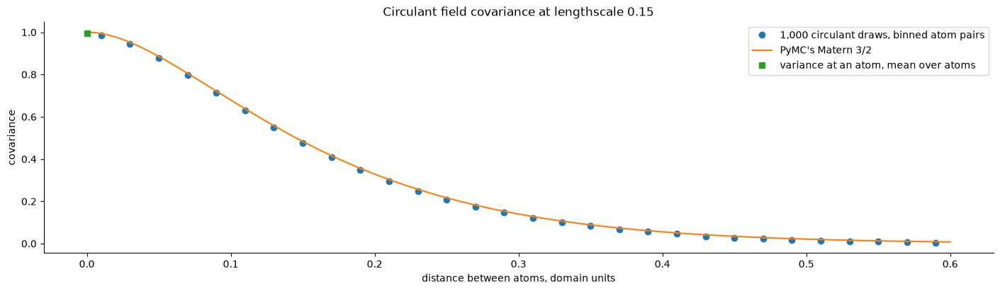

In [64]:
CHECK_LENGTHSCALE = 0.15
CHECK_DRAWS = 1_000
CHECK_PAIRS = 50_000

check_rng = np.random.default_rng(SEED)
check_fields, _ = exact_fields(np.ones(CHECK_DRAWS), np.full(CHECK_DRAWS, CHECK_LENGTHSCALE), check_rng)
pairs = check_rng.choice(n_atoms, size=(CHECK_PAIRS, 2))
pair_distance = np.linalg.norm(atom_centroids[pairs[:, 0]] - atom_centroids[pairs[:, 1]], axis=1)
pair_covariance = (check_fields[:, pairs[:, 0]] * check_fields[:, pairs[:, 1]]).mean(axis=0)
distance_bins = np.linspace(0.0, 0.6, 31)
bin_of_pair = np.digitize(pair_distance, distance_bins) - 1
in_range = bin_of_pair < len(distance_bins) - 1
binned_covariance = np.bincount(bin_of_pair[in_range], weights=pair_covariance[in_range], minlength=len(distance_bins) - 1) / np.bincount(bin_of_pair[in_range], minlength=len(distance_bins) - 1)
distance_line = np.linspace(0.0, 0.6, 200)

fig, ax = plt.subplots()
ax.plot((distance_bins[:-1] + distance_bins[1:]) / 2, binned_covariance, "o", label=f"{CHECK_DRAWS:,} circulant draws, binned atom pairs")
ax.plot(distance_line, pm.gp.cov.Matern32(input_dim=1, ls=CHECK_LENGTHSCALE)(distance_line[:, None], np.zeros((1, 1))).eval()[:, 0], label="PyMC's Matern 3/2")
ax.plot(0.0, check_fields.var(axis=0).mean(), "s", label="variance at an atom, mean over atoms")
ax.set(xlabel="distance between atoms, domain units", ylabel="covariance", title=f"Circulant field covariance at lengthscale {CHECK_LENGTHSCALE}")
ax.legend()

In [65]:
TRAINING_SIMULATIONS = 20_000
VALIDATION_SIMULATIONS = 1_000
TEST_SIMULATIONS = 500
EVENT_SET_SIZE = 256
SUBNATIONAL_LEVELS = ("ADM2", "ADM1")
GLOBAL_VARIABLES = ["intercept", "slopes", "field_amplitude", "field_lengthscale", "ADM2_offset_sd", "ADM1_offset_sd",
                    "naming_intercept", "naming_slope", "level_probability", "year_amplitude", "year_lengthscale", "overdispersion"]
state_sum = Aggregation(units=tuple(units["ADM1"]["gid"]),
                        rows=unit_of_atom["ADM1"],
                        columns=np.arange(n_atoms),
                        weights=np.ones(n_atoms),
                        n_cells=n_atoms)
CELLS = [f"{level} {gid}" for level in SUBNATIONAL_LEVELS for gid in units["ADM1"]["gid"]] + ["ADM0"]


def supplied_field(amplitude, lengthscale):
    """A field supplied with each draw, drawn outside the graph by ``exact_fields`` at the draw's amplitude and lengthscale."""
    return pm.Flat("field", dims="atom")


def with_exact_fields(draws, rng):
    """Global parameter draws with an exact field added at each draw's amplitude and lengthscale, and each field's clipped share of the spectrum."""
    fields, clipped_share = exact_fields(draws["field_amplitude"].to_numpy().ravel(),
                                         draws["field_lengthscale"].to_numpy().ravel(),
                                         rng)

    return draws.assign(field=(("chain", "draw", "atom"), fields.reshape(*draws["field_amplitude"].shape, n_atoms))), clipped_share


def build_simulator_model():
    """The fitted model run forward from supplied fields: recorded events by year, and by reporting level and state."""
    with pm.Model(coords=COORDS | {"cell": CELLS}) as model:
        recorded = recorded_intensity(field_prior=supplied_field)
        counts = annual_count(recorded)
        by_cell = pt.concatenate([*[state_sum.aggregate_symbolic(recorded[LEVELS.index(level)]) for level in SUBNATIONAL_LEVELS],
                                  recorded[LEVELS.index("ADM0")].sum()[None]])
        pm.Multinomial("cell_count",
                       n=counts.sum(),
                       p=by_cell / by_cell.sum(),
                       dims="cell")

    return model


def build_event_simulator_model():
    """The fitted model run forward from supplied fields to a record: recorded events per year and per level, and a set of events' cells and years."""
    with pm.Model(coords=COORDS | {"event": np.arange(EVENT_SET_SIZE)}) as model:
        recorded = recorded_intensity(field_prior=supplied_field)
        counts = annual_count(recorded)
        total = counts.sum()
        pm.Multinomial("level_count",
                       n=total,
                       p=recorded.sum(axis=1) / recorded.sum(),
                       dims="level")
        # Each event's (level, atom) cell, level-major, drawn from the recorded intensity.
        pm.Categorical("event_cell",
                       p=recorded.ravel() / recorded.sum(),
                       dims="event")
        # A record with no events has no years to draw from, and its event set is discarded below.
        pm.Categorical("event_year",
                       p=pt.switch(pt.gt(total, 0), counts / pt.maximum(total, 1), pt.ones(YEARS) / YEARS),
                       dims="event")

    return model


simulation_rng = np.random.default_rng(SEED)
with build_event_simulator_model():
    global_draws = pm.sample_prior_predictive(draws=TRAINING_SIMULATIONS + VALIDATION_SIMULATIONS + TEST_SIMULATIONS,
                                              var_names=GLOBAL_VARIABLES,
                                              random_seed=simulation_rng)["prior"].to_dataset()
simulator_inputs, clipped_share = with_exact_fields(global_draws, simulation_rng)

# The offsets and the year effect, absent from the inputs, are drawn from their priors.
with build_event_simulator_model():
    simulations = pm.sample_posterior_predictive(xr.DataTree.from_dict({"posterior": simulator_inputs}),
                                                 var_names=["annual_count", "level_count", "event_cell", "event_year"],
                                                 freeze_vars=["field"],
                                                 random_seed=simulation_rng)

pd.Series({
    "draws with over 1% of the spectrum clipped": int((clipped_share > 0.01).sum()),
    "largest clipped share": clipped_share.max(),
}).round(4)

Sampling: [ADM1_offset_sd, ADM2_offset_sd, field_amplitude, field_lengthscale, intercept, level_probability, naming_intercept, naming_slope, overdispersion, slopes, year_amplitude, year_lengthscale]
INFO:pymc.sampling.forward:Sampling: [ADM1_offset_sd, ADM2_offset_sd, field_amplitude, field_lengthscale, intercept, level_probability, naming_intercept, naming_slope, overdispersion, slopes, year_amplitude, year_lengthscale]


  0%|          | 0/21500 [00:00<?, ?it/s]

Sampling: [ADM1_offset_standard, ADM2_offset_standard, annual_count, event_cell, event_year, level_count, year_effect_hsgp_coeffs]
INFO:pymc.sampling.forward:Sampling: [ADM1_offset_standard, ADM2_offset_standard, annual_count, event_cell, event_year, level_count, year_effect_hsgp_coeffs]


Output()

draws with over 1% of the spectrum clipped   260.00
largest clipped share                          0.07
dtype: float64

In [98]:
GLOBAL_NAMES = ["intercept", "river slope", "log field amplitude", "log field lengthscale", "log ADM2 offset sd", "log ADM1 offset sd",
                "naming intercept", "naming slope", "log ADM2 over ADM0 level ratio", "log ADM1 over ADM0 level ratio",
                "log year amplitude", "log year lengthscale", "log overdispersion"]


def global_parameters(draws):
    """The 13 global parameters, one row per draw, on the scales the model samples them on, in GLOBAL_NAMES order."""
    level = draws["level_probability"].transpose(..., "level").to_numpy()

    return np.column_stack([
        draws["intercept"].to_numpy(),
        draws["slopes"].sel(covariate=COVARIATE_NAMES[0]).to_numpy(),
        np.log(draws["field_amplitude"].to_numpy()),
        np.log(draws["field_lengthscale"].to_numpy()),
        np.log(draws["ADM2_offset_sd"].to_numpy()),
        np.log(draws["ADM1_offset_sd"].to_numpy()),
        draws["naming_intercept"].to_numpy(),
        draws["naming_slope"].to_numpy(),
        np.log(level[:, 0] / level[:, 2]),
        np.log(level[:, 1] / level[:, 2]),
        np.log(draws["year_amplitude"].to_numpy()),
        np.log(draws["year_lengthscale"].to_numpy()),
        np.log(draws["overdispersion"].to_numpy()),
    ]).astype("float32")


def union_features(atoms):
    """The ground a set of atoms covers: centroid, log atom count, log population and mean river covariate."""
    if len(atoms) == 0:
        return np.zeros(5)

    return np.array([*atom_centroids[atoms].mean(axis=0),
                     np.log(len(atoms)),
                     np.log1p(population[atoms].sum()),
                     covariates[atoms, 0].mean()])


def event_features(level_index, ground, event_years):
    """One row per event, over any leading axes: its year, its level as one-hot, and the features of the ground it names."""
    return np.concatenate([((event_years - years.mean()) / years.std())[..., None],
                           np.eye(len(LEVELS))[level_index],
                           ground], axis=-1).astype("float32")


# A subnational event names its center's unit and that unit's nearest neighbors at its level, as many units as a real event there names.
units_named = {level: np.array([len(named[level]) for named, reported in zip(record["named"], record["level"], strict=True) if reported == level])
               for level in SUBNATIONAL_LEVELS}
union_sizes = {level: np.unique(units_named[level], return_counts=True) for level in SUBNATIONAL_LEVELS}
atoms_of_unit = {level: [overlaps[level]["atom"].to_numpy()[overlaps[level]["unit"].to_numpy() == unit] for unit in range(n_units[level])]
                 for level in SUBNATIONAL_LEVELS}
unit_xy = {level: (np.column_stack([centers.x, centers.y]) - atom_xy.min(axis=0)) / np.ptp(atom_xy, axis=0).max()
           for level, centers in ((level, units[level].to_crs(PROJECTED_CRS).geometry.centroid) for level in SUBNATIONAL_LEVELS)}
nearest_units = {level: np.argsort(np.linalg.norm(unit_xy[level][:, None] - unit_xy[level][None], axis=2), axis=1)
                 for level in SUBNATIONAL_LEVELS}
# The ground of every union an event can name, by center unit and union size, read from the overlaps as a real record's is.
union_ground = {level: np.stack([[union_features(np.unique(np.concatenate([atoms_of_unit[level][member] for member in nearest_units[level][unit, :size]])))
                                  for size in union_sizes[level][0]]
                                 for unit in range(n_units[level])])
                for level in SUBNATIONAL_LEVELS}
country_ground = union_features(np.arange(n_atoms))


def named_ground(event_cell, rng):
    """The ground each event names, over any leading axes: a union of units around its center, or the whole country."""
    level_index, atom = np.divmod(event_cell, n_atoms)
    ground = np.broadcast_to(country_ground, (*event_cell.shape, len(country_ground))).copy()
    for level in SUBNATIONAL_LEVELS:
        at_level = level_index == LEVELS.index(level)
        sizes, counts = union_sizes[level]
        ground[at_level] = union_ground[level][unit_of_atom[level][atom[at_level]],
                                               rng.choice(len(sizes), size=at_level.sum(), p=counts / counts.sum())]

    return ground


simulated_draws = az.extract(simulations, group="posterior_predictive")
event_cell = simulated_draws["event_cell"].transpose("sample", "event").to_numpy()
annual = simulated_draws["annual_count"].transpose("sample", "year").to_numpy()
recorded_any = annual.sum(axis=1) > 0
simulated = {
    "parameters": global_parameters(global_draws.stack(sample=("chain", "draw"))),
    "events": event_features(event_cell // n_atoms,
                             named_ground(event_cell, np.random.default_rng(SEED)),
                             years[simulated_draws["event_year"].transpose("sample", "event").to_numpy()]) * recorded_any[:, None, None],
    "counts": np.log1p(np.column_stack([annual, simulated_draws["level_count"].transpose("sample", "level").to_numpy()])).astype("float32"),
}
splits = np.cumsum([TRAINING_SIMULATIONS, VALIDATION_SIMULATIONS])
training, validation, test = ({key: values[start:stop] for key, values in simulated.items()}
                              for start, stop in zip([0, *splits], [*splits, None]))

simulated_totals = annual.sum(axis=1)
pd.Series({
    "simulations": len(simulated["parameters"]),
    "features per event": simulated["events"].shape[2],
    "simulations with no recorded event": int((~recorded_any).sum()),
    "median recorded events": float(np.median(simulated_totals)),
    "share of simulations within a factor of 3 of 452": float((np.abs(np.log(np.maximum(simulated_totals, 1) / 452)) < np.log(3)).mean()),
}).round(2)

simulations                                        21500.00
features per event                                     9.00
simulations with no recorded event                     3.00
median recorded events                              1196.00
share of simulations within a factor of 3 of 452       0.43
dtype: float64

/Users/jessegrabowski/mambaforge/envs/climate-risk/lib/python3.12/site-packages/seaborn/axisgrid.py:123: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


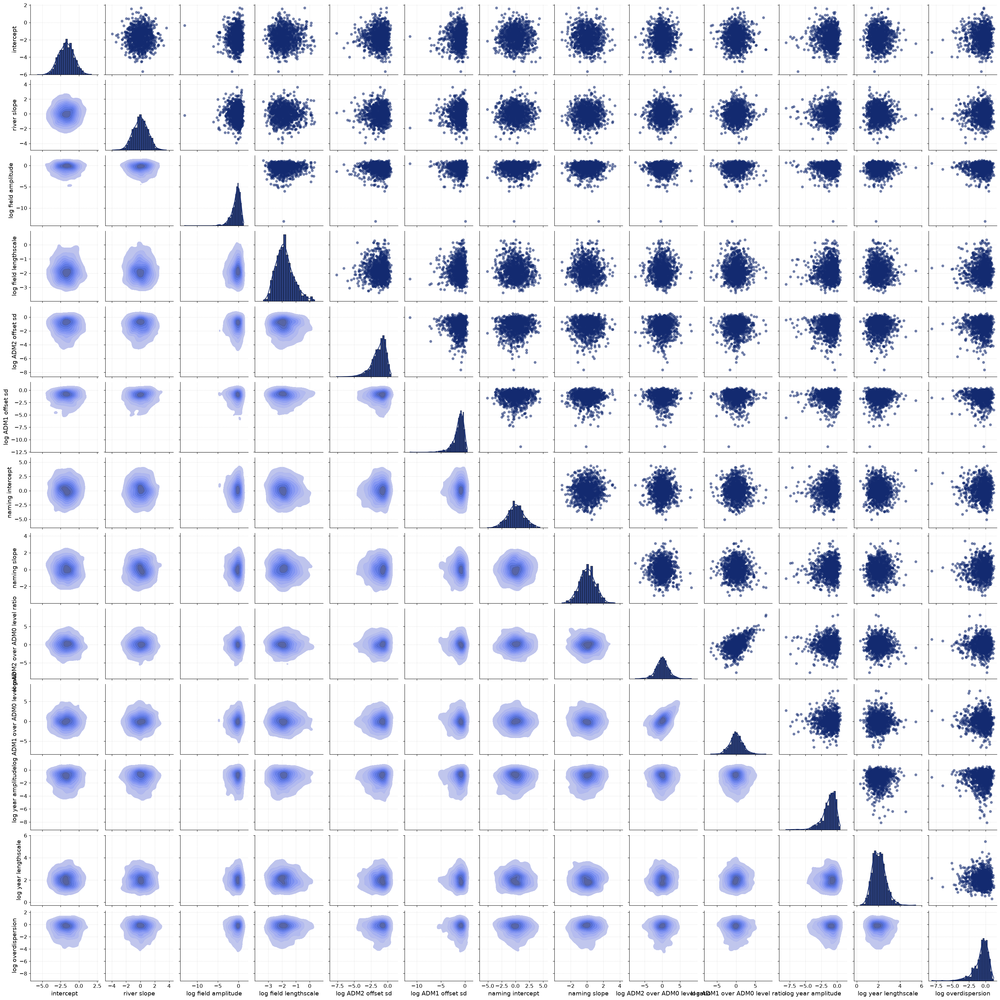

In [67]:
PRIOR_PAIRS_DRAWS = 1_000

# Prior draws of the targets, to check the simulator spans what it should before anything is trained on it.
bf.diagnostics.plots.pairs_samples(samples={"parameters": training["parameters"][:PRIOR_PAIRS_DRAWS]},
                                   variable_names=GLOBAL_NAMES)
plt.show()

In [99]:
def observed_cell_counts():
    """The real record's events by level and state, a record naming several states split equally among them."""
    cells = pd.Series(0.0, index=CELLS)
    for level, provinces in zip(record["level"], record["provinces"], strict=True):
        if level == "ADM0" or not provinces:
            cells["ADM0"] += 1.0
            continue
        for province in provinces:
            cells[f"{level} {units['ADM1']['gid'].iloc[province]}"] += 1.0 / len(provinces)

    return cells.to_numpy()


def observed_record(rng):
    """The real record as the estimator sees it: an event set drawn with replacement from its events, and its counts."""
    level_index, ground = zip(*[(level, union_features(cells - level * n_atoms))
                                for level, cells in map(union_cells, record["named"])], strict=True)
    events = event_features(np.array(level_index), np.stack(ground), record["year"].to_numpy())
    level_counts = np.bincount(level_index, minlength=len(LEVELS))

    return {
        "events": events[rng.choice(len(events), size=EVENT_SET_SIZE)][None],
        "counts": np.log1p(np.concatenate([annual_observed, level_counts]))[None].astype("float32"),
    }


observed = observed_record(np.random.default_rng(SEED))

pd.Series({
    "recorded events": annual_observed.sum(),
    "events in the set": observed["events"].shape[1],
    "median atoms an event names, real": float(np.median(np.exp(observed["events"][0, :, 6]))),
    "median atoms an event names, simulated": float(np.median(np.exp(test["events"][:, :, 6][test["events"][:, :, 6] != 0]))),
}).round(1)

recorded events                          452.00
events in the set                        256.00
median atoms an event names, real        262.00
median atoms an event names, simulated   523.00
dtype: float64

In [100]:
NPE_EPOCHS = 100
NPE_BATCH = 256
SUMMARY_DIM = 32

workflow = bf.BasicWorkflow(inference_network=bf.networks.CouplingFlow(),
                            summary_network=bf.networks.SetTransformer(summary_dim=SUMMARY_DIM),
                            inference_variables=["parameters"],
                            summary_variables=["events"],
                            inference_conditions=["counts"],
                            standardize=["parameters", "events", "counts"])
history = workflow.fit_offline(training,
                               epochs=NPE_EPOCHS,
                               batch_size=NPE_BATCH,
                               validation_data=validation)

INFO:bayesflow:Fitting on dataset instance of OfflineDataset.
INFO:bayesflow:Building on a test batch.


Epoch 1/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 12s 115ms/step - loss: 21.8604 - val_loss: 19.1481
Epoch 2/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - loss: 17.8578 - val_loss: 16.2883
Epoch 3/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - loss: 16.2069 - val_loss: 15.3166
Epoch 4/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - loss: 15.5569 - val_loss: 14.8235
Epoch 5/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - loss: 15.1265 - val_loss: 14.5232
Epoch 6/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 5s 64ms/step - loss: 14.3041 - val_loss: 13.8247
Epoch 7/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 5s 64ms/step - loss: 13.6908 - val_loss: 13.0113
Epoch 8/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 5s 64ms/step - loss: 13.2294 - val_loss: 12.9660
Epoch 9/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 5s 65ms/step - loss: 12.8635 - val_loss: 12.4558
Epoch 10/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 5s 65ms/step - loss: 12.5411 - val_loss: 12.2841
Epoch 11/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 5s 68ms/step - loss: 12.3214 - val_loss: 12.0105
Epoch 12/100
79/79 ━━━━━━━━━

79/79 ━━━━━━━━━━━━━━━━━━━━ 7s 90ms/step - loss: 9.3694 - val_loss: 10.5503
Epoch 68/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 7s 88ms/step - loss: 9.3460 - val_loss: 10.4816
Epoch 69/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 7s 85ms/step - loss: 9.3183 - val_loss: 10.4432
Epoch 70/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 10s 125ms/step - loss: 9.3093 - val_loss: 10.4149
Epoch 71/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 9s 114ms/step - loss: 9.2935 - val_loss: 10.4388
Epoch 72/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 8s 98ms/step - loss: 9.2761 - val_loss: 10.4440
Epoch 73/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 9s 108ms/step - loss: 9.2553 - val_loss: 10.4372
Epoch 74/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 9s 114ms/step - loss: 9.2478 - val_loss: 10.4567
Epoch 75/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 7s 95ms/step - loss: 9.2435 - val_loss: 10.4669
Epoch 76/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 7s 91ms/step - loss: 9.2192 - val_loss: 10.4464
Epoch 77/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 7s 87ms/step - loss: 9.2274 - val_loss: 10.4660
Epoch 78/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 

INFO:bayesflow:Training completed in 12.23 minutes.


In [101]:
TEST_DRAWS = 1_000

# Drawn once and passed to every diagnostic, so none of them redraws.
test_samples = workflow.sample(conditions=test, num_samples=TEST_DRAWS, batch_size=100, seed=SEED)

Summarizing:   0%|          | 0/5 [00:00<?, ?batch/s]

Sampling:   0%|          | 0/5 [00:00<?, ?batch/s]

INFO:bayesflow:Sampling completed in 0.56 seconds.


/Users/jessegrabowski/mambaforge/envs/climate-risk/lib/python3.12/site-packages/bayesflow/diagnostics/plots/loss.py:176: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


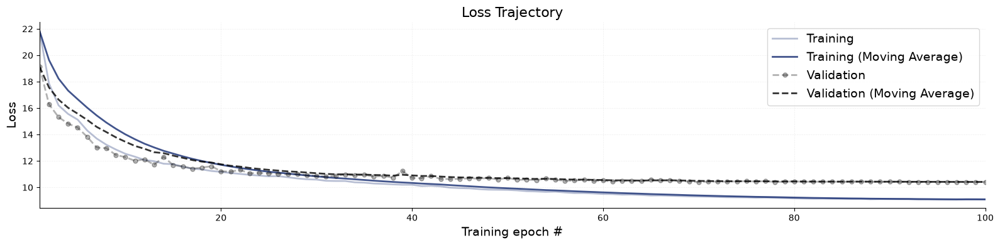

In [102]:
bf.diagnostics.plots.loss(history)
plt.show()

/Users/jessegrabowski/mambaforge/envs/climate-risk/lib/python3.12/site-packages/bayesflow/diagnostics/plots/calibration_ecdf.py:234: UserWarning: The figure layout has changed to tight
  plot_data["fig"].tight_layout()


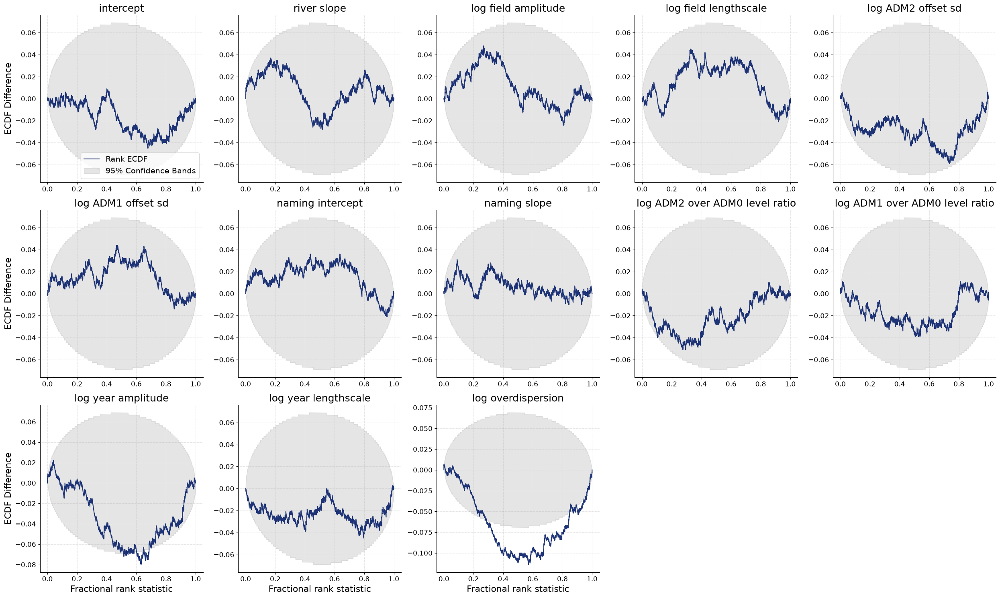

In [103]:
bf.diagnostics.plots.calibration_ecdf(test_samples, test, difference=True, variable_names=GLOBAL_NAMES)
plt.show()

/Users/jessegrabowski/mambaforge/envs/climate-risk/lib/python3.12/site-packages/bayesflow/diagnostics/plots/recovery.py:207: UserWarning: The figure layout has changed to tight
  plot_data["fig"].tight_layout()


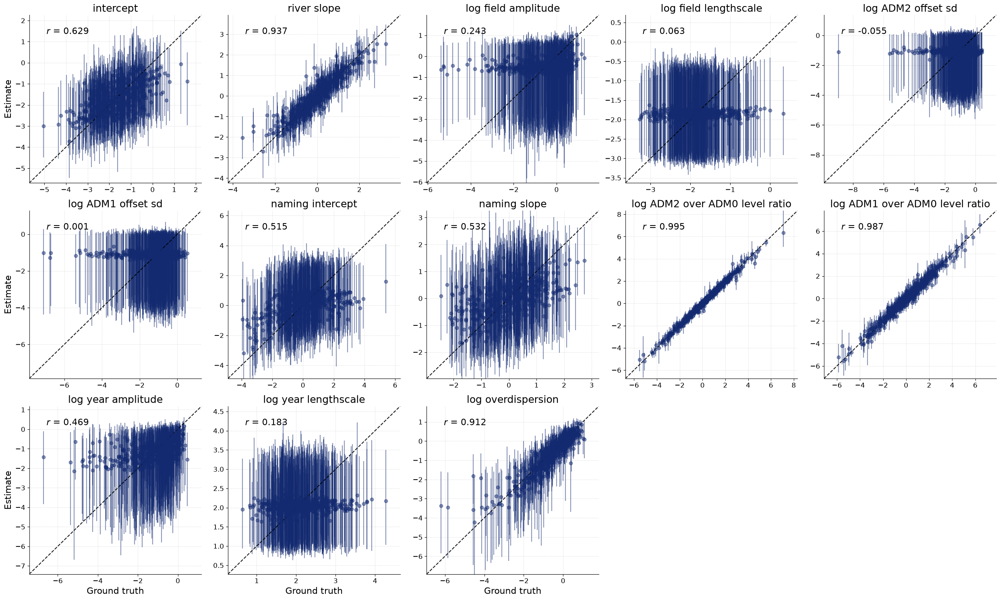

In [104]:
bf.diagnostics.plots.recovery(test_samples, test, variable_names=GLOBAL_NAMES)
plt.show()

/Users/jessegrabowski/mambaforge/envs/climate-risk/lib/python3.12/site-packages/bayesflow/diagnostics/plots/z_score_contraction.py:169: UserWarning: The figure layout has changed to tight
  plot_data["fig"].tight_layout()


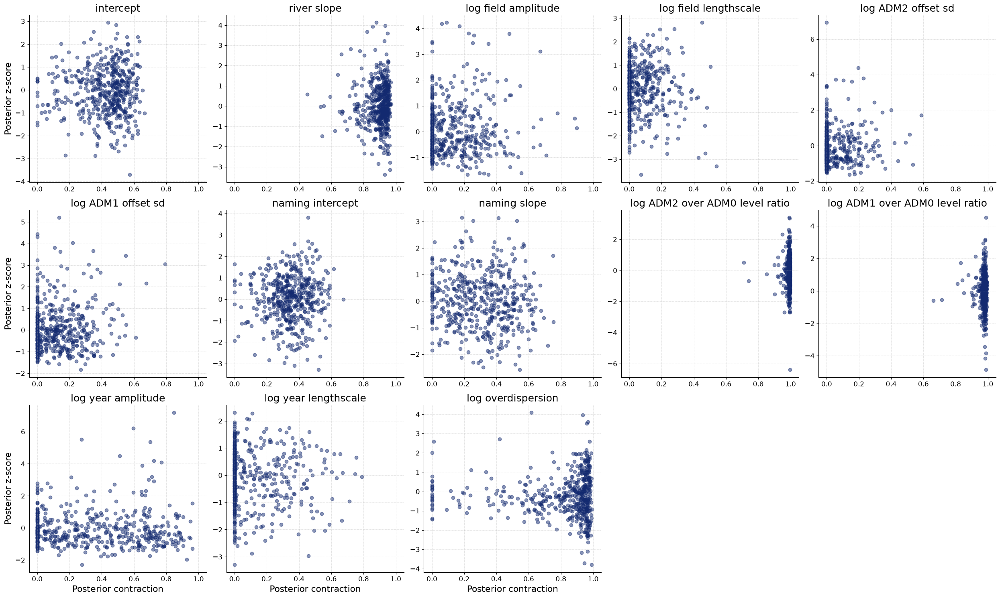

In [105]:
bf.diagnostics.plots.z_score_contraction(test_samples, test, variable_names=GLOBAL_NAMES)
plt.show()

In [106]:
workflow.compute_default_diagnostics(test_data=test, samples=test_samples, variable_names=GLOBAL_NAMES).round(2)

,intercept,river slope,log field amplitude,log field lengthscale,log ADM2 offset sd,log ADM1 offset sd,naming intercept,naming slope,log ADM2 over ADM0 level ratio,log ADM1 over ADM0 level ratio,log year amplitude,log year lengthscale,log overdispersion
NRMSE,0.76,0.32,0.98,0.99,1.06,0.99,0.83,0.85,0.09,0.15,0.86,0.99,0.35
Log Gamma,3.07,1.81,2.70,3.35,1.11,3.21,3.58,2.98,0.57,4.18,-1.47,1.83,-8.07
Calibration Error,0.02,0.01,0.02,0.00,0.01,0.01,0.01,0.01,0.02,0.01,0.03,0.01,0.02
Posterior Contraction,0.46,0.91,0.07,0.02,0.00,0.10,0.35,0.32,0.99,0.98,0.30,0.00,0.91


In [107]:
NPE_DRAWS = 2_000


def as_global_draws(values):
    """Global parameter draws, one row per draw, as a posterior along one draw axis."""
    return xr.DataTree.from_dict({"posterior": xr.Dataset({name: ("draw", values[:, index]) for index, name in enumerate(GLOBAL_NAMES)})})


npe_samples = workflow.sample(num_samples=NPE_DRAWS, conditions=observed, seed=SEED)
npe_draws = npe_samples["parameters"][0]

Summarizing:   0%|          | 0/1 [00:00<?, ?batch/s]

Sampling:   0%|          | 0/1 [00:00<?, ?batch/s]

INFO:bayesflow:Sampling completed in 0.06 seconds.


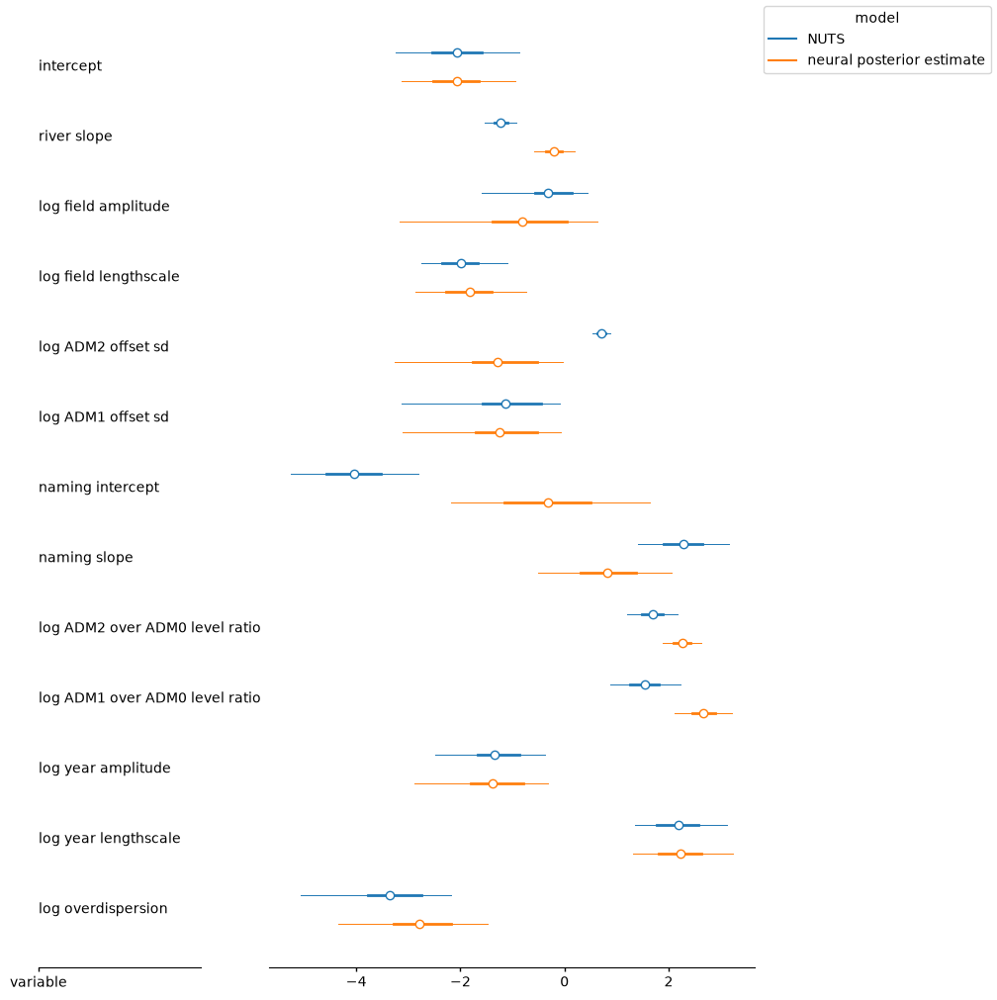

In [108]:
forest = az.plot_forest({"NUTS": as_global_draws(global_parameters(az.extract(fit))),
                         "neural posterior estimate": as_global_draws(npe_draws)},
                        sample_dims=["draw"],
                        aes={"color": ["model"]},
                        figure_kwargs={"figsize": (10, 10)})
forest.add_legend("model")
plt.show()

/Users/jessegrabowski/mambaforge/envs/climate-risk/lib/python3.12/site-packages/seaborn/axisgrid.py:123: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


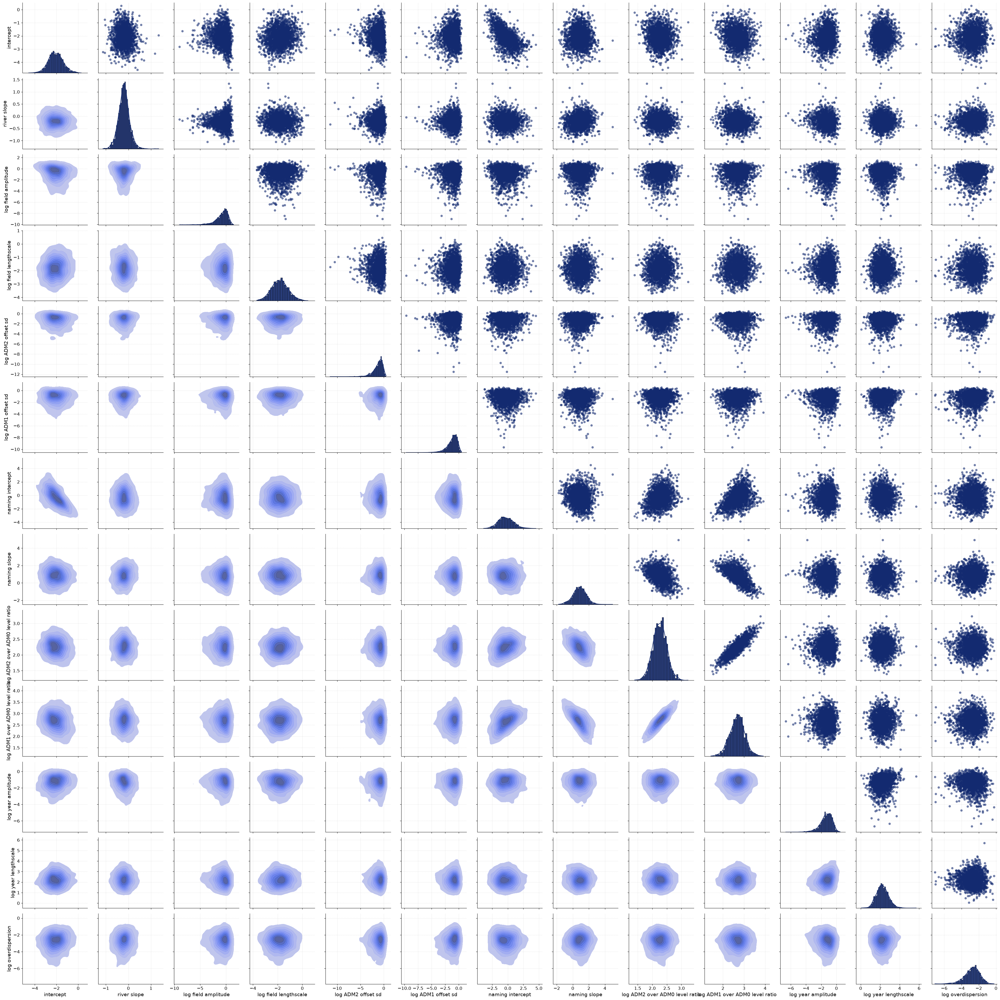

In [109]:
bf.diagnostics.plots.pairs_posterior(npe_samples, variable_names=GLOBAL_NAMES)
plt.show()

Summarizing:   0%|          | 0/1 [00:00<?, ?batch/s]

Summarizing:   0%|          | 0/1 [00:00<?, ?batch/s]

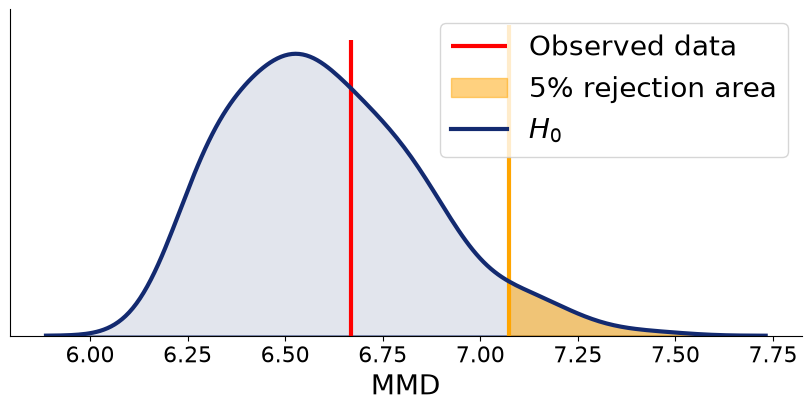

In [110]:
MMD_NULL_SAMPLES = 1_000

# The null is the summary distance from one held-out simulation to all of them; the real record is scored the same way.
np.random.seed(SEED)
mmd_observed, mmd_null = bf.diagnostics.metrics.summary_space_comparison(observed_data=observed,
                                                                         reference_data=validation,
                                                                         approximator=workflow.approximator,
                                                                         num_null_samples=MMD_NULL_SAMPLES)
bf.diagnostics.plots.mmd_hypothesis_test(mmd_null, mmd_observed=mmd_observed)
plt.show()

In [111]:
FIXED_ADM2_OFFSET_SD = 0.3926
FIXED_FIT_PATH = Path(f"fits/13_india_nuts_adm2_offset_sd_{FIXED_ADM2_OFFSET_SD:.2f}.nc")

# The fitted model with the district offset scale held fixed.
fixed_offset_model = pm.do(event_detection_model, {"ADM2_offset_sd": FIXED_ADM2_OFFSET_SD})
if FIXED_FIT_PATH.exists():
    fixed_offset_fit = az.from_netcdf(FIXED_FIT_PATH)
else:
    with fixed_offset_model:
        fixed_offset_fit = pm.sample(**sample_kwargs)
    fixed_offset_fit.to_netcdf(FIXED_FIT_PATH)

az.summary(fixed_offset_fit, var_names=["intercept", "slopes", "naming_intercept", "naming_slope", "level_probability", "ADM1_offset_sd"])

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
intercept,-1.9,0.81,-3.2,-0.59,117,247,1.07,0.075,0.024
slopes[log distance to river],-0.85,0.167,-1.1,-0.58,1032,1003,1.00,0.0052,0.0035
naming_intercept,-1.9,1.4,-3.7,0.68,72,130,1.09,0.17,0.092
naming_slope,1,0.73,-0.25,2.1,191,382,1.05,0.053,0.028
level_probability[ADM2],0.395,0.047,0.32,0.47,135,420,1.05,0.004,0.0011
level_probability[ADM1],0.55,0.061,0.45,0.64,117,324,1.06,0.0057,0.0016
level_probability[ADM0],0.056,0.021,0.028,0.093,142,244,1.05,0.0016,0.00065
ADM1_offset_sd,1,0.34,0.43,1.5,135,293,1.05,0.029,0.011


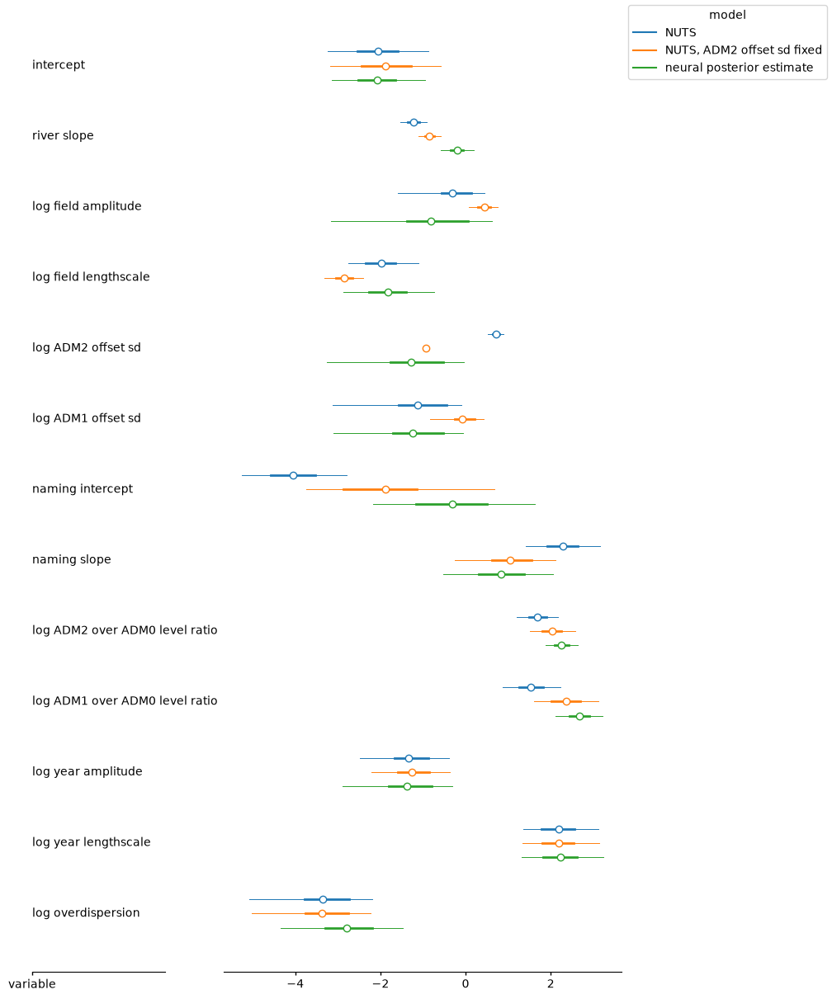

In [112]:
fixed_offset_draws = az.extract(fixed_offset_fit)
fixed_offset_draws["ADM2_offset_sd"] = ("sample", np.full(fixed_offset_draws.sizes["sample"], FIXED_ADM2_OFFSET_SD))

forest = az.plot_forest({"NUTS": as_global_draws(global_parameters(az.extract(fit))),
                         "NUTS, ADM2 offset sd fixed": as_global_draws(global_parameters(fixed_offset_draws)),
                         "neural posterior estimate": as_global_draws(npe_draws)},
                        sample_dims=["draw"],
                        aes={"color": ["model"]},
                        figure_kwargs={"figsize": (10, 12)})
forest.add_legend("model")
plt.show()

Holding the district offset scale at 0.39 moves NUTS's river slope from -1.22 (sd 0.19) to -0.85 (0.17), about a third of the way to the neural estimate of -0.20. The variation the district offsets carried goes to the field and the state offsets: the field's amplitude rises from 0.73 to 1.55, its lengthscale falls from 0.14 to 0.058 of the domain, below the 0.07 the Hilbert space basis resolves, and the state offset scale rises from 0.32 to 0.92. The detection parameters move toward the neural estimates. The naming intercept rises from -4.05 to -1.88 against the neural -0.31, the naming slope falls from 2.28 to 1.05 against 0.83, and the level ratios rise to 2.03 and 2.36 against 2.26 and 2.67. The fit mixes worse than the original: the naming intercept reaches an r-hat of 1.09 with a bulk ESS of 72, and the intercept and level probabilities 1.05 to 1.07, while the river slope's r-hat is 1.00 with a bulk ESS of 1,032.

In [113]:
RETRODICTION_DRAWS = 500


def model_parameters(values):
    """Global parameter draws mapped back to the model's own variables, as one chain of a posterior."""
    level = np.exp(np.column_stack([values[:, 8], values[:, 9], np.zeros(len(values))]))

    return xr.Dataset({
        "intercept": (("chain", "draw"), values[None, :, 0]),
        "slopes": (("chain", "draw", "covariate"), values[None, :, 1, None]),
        "field_amplitude": (("chain", "draw"), np.exp(values[None, :, 2])),
        "field_lengthscale": (("chain", "draw"), np.exp(values[None, :, 3])),
        "ADM2_offset_sd": (("chain", "draw"), np.exp(values[None, :, 4])),
        "ADM1_offset_sd": (("chain", "draw"), np.exp(values[None, :, 5])),
        "naming_intercept": (("chain", "draw"), values[None, :, 6]),
        "naming_slope": (("chain", "draw"), values[None, :, 7]),
        "level_probability": (("chain", "draw", "level"), (level / level.sum(axis=1, keepdims=True))[None]),
        "year_amplitude": (("chain", "draw"), np.exp(values[None, :, 10])),
        "year_lengthscale": (("chain", "draw"), np.exp(values[None, :, 11])),
        "overdispersion": (("chain", "draw"), np.exp(values[None, :, 12])),
    }, coords={"covariate": list(COVARIATE_NAMES), "level": list(LEVELS)})


# Only the globals are estimated, so the field is drawn at each draw's scales, and the offsets and the year effect from their priors.
retrodiction_rng = np.random.default_rng(SEED)
retrodiction_inputs, _ = with_exact_fields(model_parameters(npe_draws[:RETRODICTION_DRAWS]), retrodiction_rng)
with build_simulator_model():
    retrodicted = pm.sample_posterior_predictive(xr.DataTree.from_dict({"posterior": retrodiction_inputs}),
                                                 var_names=["annual_count", "cell_count"],
                                                 freeze_vars=["field"],
                                                 random_seed=retrodiction_rng)
retrodicted["observed_data"] = xr.Dataset({"annual_count": ("year", annual_observed),
                                           "cell_count": ("cell", observed_cell_counts())},
                                          coords={"year": years, "cell": CELLS})

  0%|          | 0/500 [00:00<?, ?it/s]

Sampling: [ADM1_offset_standard, ADM2_offset_standard, annual_count, cell_count, year_effect_hsgp_coeffs]
INFO:pymc.sampling.forward:Sampling: [ADM1_offset_standard, ADM2_offset_standard, annual_count, cell_count, year_effect_hsgp_coeffs]


Output()

In [114]:
ESTIMATORS = ["NUTS", "NPE"]


def as_one_chain(predictive, draws):
    """The first ``draws`` predictive draws, as one chain."""
    stacked = predictive.stack(sample=("chain", "draw")).isel(sample=slice(None, draws)).drop_vars(["sample", "chain", "draw"])

    return stacked.rename(sample="draw").expand_dims(chain=[0]).assign_coords(draw=np.arange(draws))


# NUTS's posterior holds the field, the offsets and the year effect, so its retrodiction keeps every latent at its fitted value.
with build_simulator_model():
    nuts_retrodicted = pm.sample_posterior_predictive(fit,
                                                      var_names=["annual_count", "cell_count"],
                                                      freeze_vars=["field"],
                                                      random_seed=SEED)

retrodiction_comparison = xr.DataTree.from_dict({
    "posterior_predictive": xr.concat([as_one_chain(predictive["posterior_predictive"].to_dataset(), RETRODICTION_DRAWS)
                                       for predictive in (nuts_retrodicted, retrodicted)],
                                      dim=pd.Index(ESTIMATORS, name="estimator")),
    "observed_data": retrodicted["observed_data"].to_dataset().expand_dims(estimator=ESTIMATORS),
})

Sampling: [annual_count, cell_count]
INFO:pymc.sampling.forward:Sampling: [annual_count, cell_count]


Output()

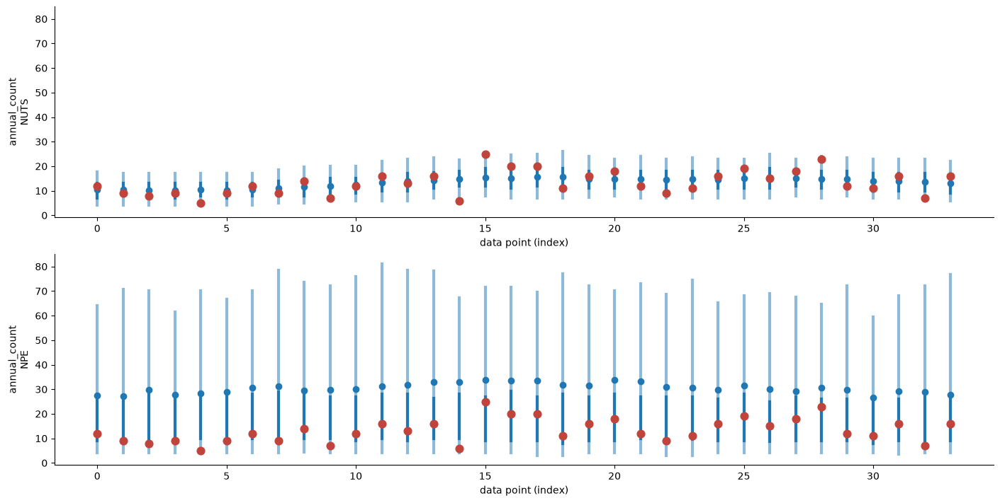

In [115]:
az.plot_ppc_interval(retrodiction_comparison,
                     var_names=["annual_count"],
                     visuals={"observed_markers": OBSERVED_MARKERS},
                     cols=["estimator"],
                     col_wrap=1,
                     figure_kwargs={"figsize": (14, 7), "sharey": True})
plt.show()

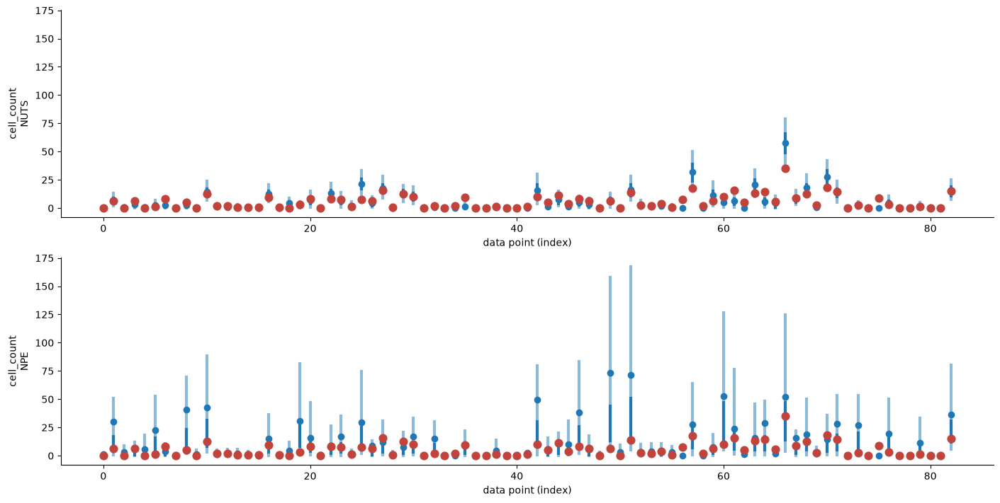

In [116]:
az.plot_ppc_interval(retrodiction_comparison,
                     var_names=["cell_count"],
                     visuals={"observed_markers": OBSERVED_MARKERS},
                     cols=["estimator"],
                     col_wrap=1,
                     figure_kwargs={"figsize": (14, 7), "sharey": True})
plt.show()

Training took 12.2 minutes, with the validation loss leveling near 10.41 from about epoch 80 while the training loss reaches 9.08. Of the 21,500 simulated fields, 260 lost more than 1% of the embedding's spectrum to clipping, the largest share 7%, all at lengthscales in the prior's tail. On held-out simulations two parameters fail calibration: the overdispersion, whose rank ECDF leaves the 95% band through the middle of the range (log gamma -8.07), and the year amplitude, whose ECDF dips below the band near rank 0.6 (log gamma -1.47). Every other parameter stays inside. The estimator recovers the level ratios, the river slope and the overdispersion, with posterior contraction of 0.91 to 0.99. The intercept contracts by 0.46, the naming intercept and slope by 0.35 and 0.32, and the year amplitude by 0.30. The state offset scale and the field's amplitude contract by 0.10 and 0.07, and the district offset scale, the field's lengthscale and the year lengthscale stay at their prior. Under HSGP simulations the field's lengthscale contracted by about 0.2. One explanation is that the estimator read the lengthscale from the approximation's basis, which an estimator trained on HSGP simulations and tested on exact ones would show as a loss of calibration in the lengthscale.

With the naming step the real record sits among the simulations in summary space: its distance to the validation simulations is 6.67, and 38% of the null distances are larger. The estimates on it move further from NUTS. The intercept, the field, the state offset scale, the year effect and the overdispersion agree with NUTS to within 0.7 of a NUTS standard deviation. The river slope is -0.20 (sd 0.25) against NUTS's -1.22 (0.19). The naming intercept is -0.31 (1.22) against -4.05 (0.78), and the naming slope 0.83 (0.81) against 2.28 (0.55), so the estimator puts detection high and nearly flat in population. The level ratios are 2.26 (0.24) and 2.67 (0.35) against 1.69 and 1.53, a level split of 0.38, 0.58 and 0.04 against NUTS's 0.49, 0.42 and 0.09. The district offset scale stays near its prior, -1.28 (1.15) on the log scale against 0.71 (0.11).

A record inside the simulations' range that still gives different estimates says the simulator and the NUTS likelihood are different models of the record. NUTS treats a record's union as coarsening at random: the union says only that the center lies somewhere inside it, and every atom in it counts by its share of the recorded intensity. The naming step puts the center in the middle of a compact union whose size is drawn independently of the event. The parameters that move most, detection and the river slope, are the ones that read where in a union events fall.

The NPE retrodiction measures the prior on the latents as much as the fit. The estimator gives the globals only, so each draw's field is drawn afresh at its amplitude and lengthscale, and the offsets and the year effect from their priors, and a draw with a large field amplitude puts a few atoms at very high rates. NUTS's posterior holds every latent, so its retrodiction through the same simulator is a posterior predictive check. The recorded total over the record has a median of 454 under NUTS, with a 94% interval of 387 to 530, and a median of 566 under NPE, with an interval of 169 to 3,082, against the record's 452. By year, both cover all 34 observed counts at 94%, and NPE's intervals are a median 95 events wide against NUTS's 19. By level and state, a record naming several states is split equally among them. NUTS covers 84% of the 83 cells at 94% with intervals a median 6 events wide, and NPE 93% with intervals 18 wide. NUTS puts 37 to 85 ADM1 events in Uttar Pradesh against 35 recorded and too many ADM2 events there, 10 to 34 against 8, and too few ADM2 events in Jammu and Kashmir, 0 to 5 against 9. Most of the remaining misses are units the simulator cannot reach. The simulator credits an event to the state that covers most of its center atom, and Chandigarh and Daman and Diu cover most of no atom on the 25 km lattice while Delhi and Puducherry cover most of two each. Those four recorded 23 events at either level, against NUTS upper bounds of at most two per cell.